## Data View

In [ ]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path("/home/ec2-user/studies/HUIFA-RNA-SEQ-new/Project/2026-nc-final").resolve()
DATASETS_DIR = (Path("/home/ec2-user/studies") / "hpp_datasets").resolve()

sys.path.append(str(PROJECT_DIR))

from phenokit.preprocessing.qc import MissingValueAnalyzer
from phenokit.preprocessing.io import read_parquet

In [2]:
pfile = f'{DATASETS_DIR}/nightingale_metabolomics/nightingale_metabolomics.parquet'
df_metabolo = read_parquet(pfile)
print(df_metabolo.shape)
df_metabolo.head()

(1644, 257)


,participant_id,cohort,research_stage,array_index,collection_timestamp,collection_date,timezone,total_c,non_hdl_c,remnant_c,...,m_hdl_pl_pct,m_hdl_c_pct,m_hdl_ce_pct,m_hdl_fc_pct,m_hdl_tg_pct,s_hdl_pl_pct,s_hdl_c_pct,s_hdl_ce_pct,s_hdl_fc_pct,s_hdl_tg_pct
0,1472239917,10k,00_00_visit,0,2019-05-19 12:54:46+03:00,2019-05-19,asia/jerusalem,5.352824,3.448706,1.383326,...,44.368760,54.186046,45.011065,9.174981,1.445194,55.116406,42.596440,32.333029,10.263411,2.287154
1,6463786344,10k,00_00_visit,0,2019-05-19 13:20:18+03:00,2019-05-19,asia/jerusalem,3.579355,2.239268,0.943939,...,45.241815,53.219694,44.646066,8.573628,1.538491,55.338602,42.258673,31.913785,10.344888,2.402726
2,8968716987,10k,00_00_visit,0,2019-05-16 13:42:25+03:00,2019-05-16,asia/jerusalem,4.369290,3.007774,1.188510,...,45.583576,52.280705,43.879349,8.401355,2.135720,55.221388,41.713239,31.881836,9.831403,3.065373
3,5105882132,10k,00_00_visit,0,2019-05-19 12:58:03+03:00,2019-05-19,asia/jerusalem,4.179214,2.521739,1.077679,...,44.810330,53.252075,44.189585,9.062490,1.937595,56.013345,41.508637,31.085629,10.423008,2.478018
4,3707738032,10k,00_00_visit,0,2019-05-16 12:14:57+03:00,2019-05-16,asia/jerusalem,6.129466,4.783657,2.084639,...,44.907475,49.782376,41.375082,8.407294,5.310149,53.823073,41.156234,30.756428,10.399806,5.020692


Overall missing rate: 0.0067 (2818 out of 422508)
=== Feature missing-rate report. (Top 10) ===
                 missing_rate  missing_count
glycerol             0.859489           1413
xxl_vldl_pl_pct      0.141727            233
xxl_vldl_c_pct       0.141727            233
xxl_vldl_ce_pct      0.141727            233
xxl_vldl_fc_pct      0.141727            233
xxl_vldl_tg_pct      0.141727            233
bohbutyrate          0.105839            174
xl_vldl_pl_pct       0.007299             12
xl_vldl_c_pct        0.007299             12
xl_vldl_ce_pct       0.007299             12
=== Sample missing-rate report. (Top 10) ===
      missing_rate  missing_count
368       0.042802             11
1341      0.042802             11
652       0.042802             11
1621      0.042802             11
849       0.042802             11
415       0.042802             11
1612      0.042802             11
163       0.038911             10
1321      0.027237              7
1400      0.027237      

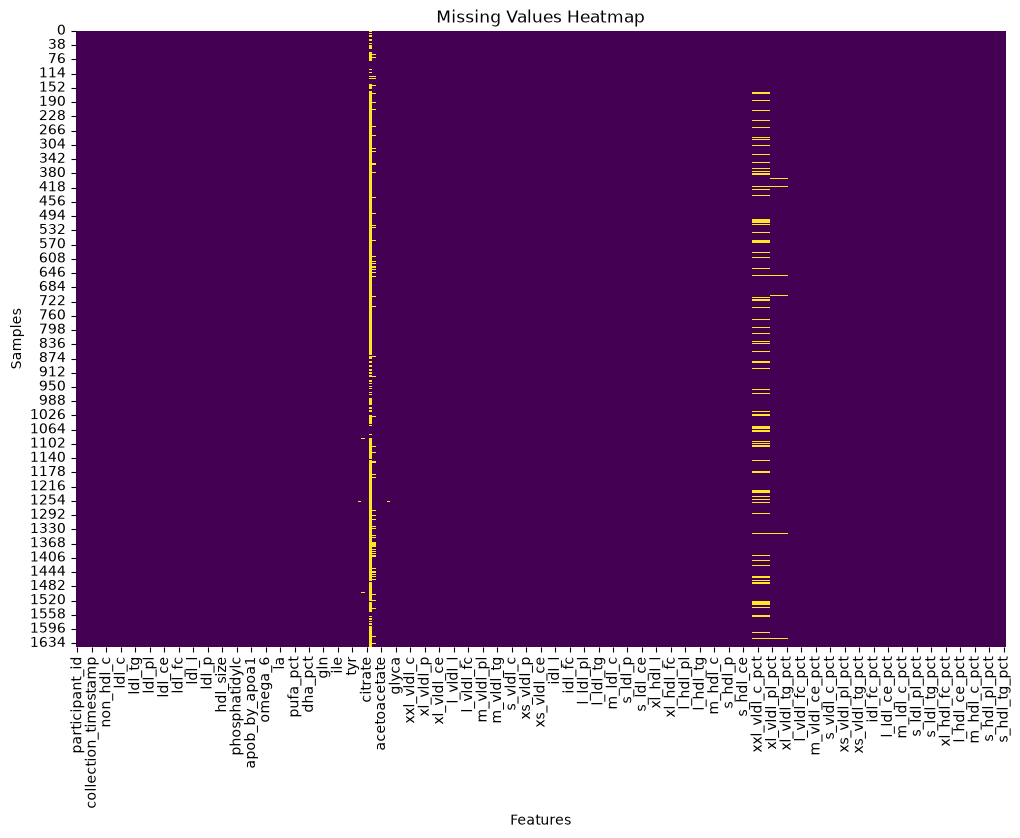

In [3]:
# Check the number and proportion of missing values
missing_analyzer = MissingValueAnalyzer(df_metabolo)
missing_analyzer.overall_missing_rate()
missing_analyzer.report_features()
missing_analyzer.report_samples()
missing_analyzer.report_heatmap()

In [4]:
metadata_col = ['participant_id', 'cohort', 'research_stage', 'array_index', 'collection_date', 'collection_timestamp', 'timezone']
df_metabolo_metadata = df_metabolo[metadata_col]
df_metabolo_features = df_metabolo.drop(columns=metadata_col)

## Imputation

In [5]:
from sklearn.impute import KNNImputer

imputer = KNNImputer(n_neighbors=5)
imputed_data = imputer.fit_transform(df_metabolo_features)
df_metabolo_features_imputed = pd.DataFrame(imputed_data, columns=df_metabolo_features.columns)
df_metabolo_features_imputed.head()

,total_c,non_hdl_c,remnant_c,vldl_c,clinical_ldl_c,ldl_c,hdl_c,total_tg,vldl_tg,ldl_tg,...,m_hdl_pl_pct,m_hdl_c_pct,m_hdl_ce_pct,m_hdl_fc_pct,m_hdl_tg_pct,s_hdl_pl_pct,s_hdl_c_pct,s_hdl_ce_pct,s_hdl_fc_pct,s_hdl_tg_pct
0,5.352824,3.448706,1.383326,0.511484,3.001999,2.065380,1.904119,0.873247,0.591148,0.137076,...,44.368760,54.186046,45.011065,9.174981,1.445194,55.116406,42.596440,32.333029,10.263411,2.287154
1,3.579355,2.239268,0.943939,0.322340,1.843260,1.295329,1.340087,0.554861,0.355390,0.089668,...,45.241815,53.219694,44.646066,8.573628,1.538491,55.338602,42.258673,31.913785,10.344888,2.402726
2,4.369290,3.007774,1.188510,0.503400,2.547635,1.819264,1.361516,0.949526,0.677819,0.129159,...,45.583576,52.280705,43.879349,8.401355,2.135720,55.221388,41.713239,31.881836,9.831403,3.065373
3,4.179214,2.521739,1.077679,0.356013,2.081810,1.444061,1.657474,0.703454,0.445493,0.112735,...,44.810330,53.252075,44.189585,9.062490,1.937595,56.013345,41.508637,31.085629,10.423008,2.478018
4,6.129466,4.783657,2.084639,1.041211,3.937880,2.699018,1.345809,1.858429,1.340619,0.220908,...,44.907475,49.782376,41.375082,8.407294,5.310149,53.823073,41.156234,30.756428,10.399806,5.020692


## Save

In [6]:
df_metabolo_metadata.reset_index(drop=True, inplace=True)
df_metabolo_features_imputed.reset_index(drop=True, inplace=True)
df_metabolo = pd.concat([df_metabolo_metadata, df_metabolo_features_imputed], axis=1)
pfile = 'processed_data/029-nightingale_metabolomics_imputed.parquet'
df_metabolo.to_parquet(pfile, index=False)

In [7]:
pfile = 'processed_data/029-nightingale_metabolomics_imputed.parquet'
df_metabolo = pd.read_parquet(pfile)
print(df_metabolo.shape)
df_metabolo.head()

(1644, 257)


,participant_id,cohort,research_stage,array_index,collection_date,collection_timestamp,timezone,total_c,non_hdl_c,remnant_c,...,m_hdl_pl_pct,m_hdl_c_pct,m_hdl_ce_pct,m_hdl_fc_pct,m_hdl_tg_pct,s_hdl_pl_pct,s_hdl_c_pct,s_hdl_ce_pct,s_hdl_fc_pct,s_hdl_tg_pct
0,1472239917,10k,00_00_visit,0,2019-05-19,2019-05-19 12:54:46+03:00,asia/jerusalem,5.352824,3.448706,1.383326,...,44.368760,54.186046,45.011065,9.174981,1.445194,55.116406,42.596440,32.333029,10.263411,2.287154
1,6463786344,10k,00_00_visit,0,2019-05-19,2019-05-19 13:20:18+03:00,asia/jerusalem,3.579355,2.239268,0.943939,...,45.241815,53.219694,44.646066,8.573628,1.538491,55.338602,42.258673,31.913785,10.344888,2.402726
2,8968716987,10k,00_00_visit,0,2019-05-16,2019-05-16 13:42:25+03:00,asia/jerusalem,4.369290,3.007774,1.188510,...,45.583576,52.280705,43.879349,8.401355,2.135720,55.221388,41.713239,31.881836,9.831403,3.065373
3,5105882132,10k,00_00_visit,0,2019-05-19,2019-05-19 12:58:03+03:00,asia/jerusalem,4.179214,2.521739,1.077679,...,44.810330,53.252075,44.189585,9.062490,1.937595,56.013345,41.508637,31.085629,10.423008,2.478018
4,3707738032,10k,00_00_visit,0,2019-05-16,2019-05-16 12:14:57+03:00,asia/jerusalem,6.129466,4.783657,2.084639,...,44.907475,49.782376,41.375082,8.407294,5.310149,53.823073,41.156234,30.756428,10.399806,5.020692
